# Proxy / ElasticNet / XGBoost test-set performance plots

This notebook is **plotting-only**. It reuses the data/result loading pattern from `3.1.proxy_z`, builds the train-z-normalized same-gene proxy on the exact saved H5 test split, and compares only the three model families:

- Proxy one-gene train-z-normalized baseline
- ElasticNet (`enet` + `enet_zbig` folders)
- XGBoost (`xgb` + `xgb_zbig` folders)


In [1]:
from pathlib import Path
import hashlib
import json
import warnings

import h5py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------------
# Project paths, matching notebook 3.1
# ---------------------------------------------------------------------
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"

X_PATH = DATA_DIR / "transcriptomics_filtered.joblib"
Y_PATH = DATA_DIR / "proteomics_matched.joblib"
PEARSON_PATH = DATA_DIR / "full_pearson100.joblib"
SPEARMAN_PATH = DATA_DIR / "full_spearman100.joblib"

MODEL_DIRS = {
    "xgb": ROOT / "results_xgb",
    "xgb_zbig": ROOT / "res_xgb_zbig",
    "enet": ROOT / "results_enet",
    "enet_zbig": ROOT / "res_enet_zbig",
}

# Output controls
FIGURE_DIR = ROOT / "model_performance_test_plots"
SAVE_FIGURES = True
COMPUTE_MISSING_R2_FROM_H5 = True  # set False to skip opening H5 files again for R2
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Proxy settings, matching notebook 3.1
USE_TRAIN_ZSCORE_PROXY_NORMALIZATION = True
ALLOW_RANDOM_SPLIT_FALLBACK = False  # keep False for fair test-set comparisons
RANDOM_SEED = 42
TEST_FRACTION = 0.20

MODEL_DISPLAY_ORDER = ["Proxy", "ElasticNet", "XGBoost"]
FAMILY_TO_DISPLAY = {"proxy": "Proxy", "enet": "ElasticNet", "xgb": "XGBoost"}

print("Root:", ROOT)
print("Data dir:", DATA_DIR)
print("Model folders:")
for name, folder in MODEL_DIRS.items():
    print(f"  {name:10s}: {folder}  exists={folder.exists()}")
print("Figure dir:", FIGURE_DIR)


Root: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison
Data dir: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\data
Model folders:
  xgb       : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\results_xgb  exists=True
  xgb_zbig  : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\res_xgb_zbig  exists=True
  enet      : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\results_enet  exists=True
  enet_zbig : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\res_enet_zbig  exists=True
Figure dir: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\model_performance_test_plots


## Utility import plus notebook-local fallbacks

The first block tries to import `utils_ccle.py` exactly like notebook 3.1. The fallback definitions below cover only what this plotting notebook needs, so no procedural-cascade helpers are included.

In [2]:
# ---------------------------------------------------------------------
# Optional import of shared CCLE utilities, same search pattern as notebook 3.1
# ---------------------------------------------------------------------
from pathlib import Path as _Path
import importlib.util as _importlib_util
import sys as _sys

_utils_candidates = []
for _candidate in [
    _Path.cwd(),
    _Path.cwd().parent,
    _Path.cwd() / "notebooks",
    _Path.cwd().parent / "notebooks",
    _Path.cwd() / "notebooks2",
    _Path.cwd().parent / "notebooks2",
]:
    _utils_candidates.append(_candidate / "utils_ccle.py")
    _utils_candidates.append(_candidate / "src" / "utils_ccle.py")

_utils_path = next((p for p in _utils_candidates if p.exists()), None)
if _utils_path is not None:
    _spec = _importlib_util.spec_from_file_location("utils_ccle", _utils_path)
    uc = _importlib_util.module_from_spec(_spec)
    _sys.modules["utils_ccle"] = uc
    _spec.loader.exec_module(uc)
    for _name in getattr(uc, "__all__", []):
        globals()[_name] = getattr(uc, _name)
    try:
        uc.set_module_globals(globals())
    except Exception:
        pass
    print("Loaded utilities:", uc.__file__)
else:
    uc = None
    print("utils_ccle.py was not found; using notebook-local fallback helpers.")


Loaded utilities: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\src\utils_ccle.py


In [3]:
# ---------------------------------------------------------------------
# Fallback helpers used only if utils_ccle did not provide them.
# ---------------------------------------------------------------------

def _define_if_missing(name, obj):
    if name not in globals():
        globals()[name] = obj


def _fallback_require_file(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path.resolve()}")
    return path


def _fallback_split_hash(samples):
    values = [str(x) for x in pd.Index(samples)]
    payload = "\n".join(values).encode("utf-8")
    return hashlib.sha1(payload).hexdigest()[:12]


def _as_python_scalar(x):
    if isinstance(x, bytes):
        return x.decode("utf-8", errors="replace")
    if isinstance(x, np.generic):
        return x.item()
    if isinstance(x, np.ndarray):
        if x.shape == ():
            return _as_python_scalar(x.item())
        if x.size == 1:
            return _as_python_scalar(x.reshape(-1)[0])
        return [_as_python_scalar(v) for v in x.reshape(-1).tolist()]
    return x


def _decode_array(values):
    arr = np.asarray(values)
    if arr.shape == ():
        return pd.Index([_as_python_scalar(arr.item())]).astype(str)
    return pd.Index([_as_python_scalar(v) for v in arr.reshape(-1)]).astype(str)


def _h5_visit_items(h5):
    items = []
    def visitor(name, obj):
        items.append((name, obj))
    h5.visititems(visitor)
    return items


def _h5_find_attr(h5, candidate_names):
    wanted = {c.lower() for c in candidate_names}
    groups = [("/", h5)] + [(name, obj) for name, obj in _h5_visit_items(h5) if hasattr(obj, "attrs")]
    for _, obj in groups:
        for key, value in obj.attrs.items():
            if str(key).lower() in wanted:
                return _as_python_scalar(value)
    return None


def _h5_find_dataset(h5, candidate_names):
    wanted = {c.lower() for c in candidate_names}
    for name, obj in _h5_visit_items(h5):
        if isinstance(obj, h5py.Dataset):
            base = Path(name).name.lower()
            if base in wanted or name.lower().replace("/", "_") in wanted:
                try:
                    return obj[()]
                except Exception:
                    return None
    return None


def _h5_find_numeric(h5, candidate_names):
    value = _h5_find_attr(h5, candidate_names)
    if value is None:
        value = _h5_find_dataset(h5, candidate_names)
    value = _as_python_scalar(value)
    try:
        return float(value)
    except Exception:
        return np.nan


def _parse_h5_filename(path, source_label):
    stem = Path(path).stem
    parts = stem.split("_")
    family = "xgb" if "xgb" in stem.lower() or "xgb" in str(source_label).lower() else "enet" if "enet" in stem.lower() or "enet" in str(source_label).lower() else str(source_label)
    protein = parts[0] if parts else stem

    normalization = None
    grid_preset = None
    select_k = np.nan

    for token in parts:
        low = token.lower()
        if low in {"none", "zscore", "ranking", "rank", "qbin50", "unknown"}:
            normalization = low
        if low in {"tiny", "fast", "current", "full"}:
            grid_preset = low
        if low.startswith("k") and low[1:].isdigit():
            select_k = int(low[1:])

    normalization = normalization or _h5_find_text_hint_from_name(stem, ["none", "zscore", "ranking", "rank", "qbin50", "unknown"])
    grid_preset = grid_preset or _h5_find_text_hint_from_name(stem, ["tiny", "fast", "current", "full"])

    run_bits = [str(source_label)]
    run_bits.append(normalization or "unknown")
    run_bits.append(grid_preset or "unknown")
    if pd.notna(select_k):
        run_bits.append(f"k{int(select_k)}")
    run_label = " | ".join(run_bits)

    return {
        "protein": protein,
        "model_family": family,
        "source_folder": str(source_label),
        "normalization": normalization,
        "grid_preset": grid_preset,
        "select_k": select_k,
        "run_label": run_label,
    }


def _h5_find_text_hint_from_name(stem, options):
    low = stem.lower()
    for opt in options:
        if f"_{opt}_" in f"_{low}_" or low.endswith(f"_{opt}"):
            return opt
    return None


def _safe_json_loads(value):
    if value is None:
        return None
    value = _as_python_scalar(value)
    if isinstance(value, (dict, list)):
        return value
    if not isinstance(value, str):
        return value
    try:
        return json.loads(value)
    except Exception:
        return value


def _fallback_read_test_samples_from_h5(path):
    candidate_names = [
        "test_samples", "test_sample_names", "test_index", "test_indices_names",
        "X_test_index", "y_test_index", "test_cell_lines", "loo_test_samples",
    ]
    with h5py.File(path, "r") as h5:
        value = _h5_find_attr(h5, candidate_names)
        if value is not None:
            return _decode_array(value)
        value = _h5_find_dataset(h5, candidate_names)
        if value is not None:
            return _decode_array(value)
    return None


def _fallback_load_h5_summary(path, source_label):
    path = Path(path)
    row = _parse_h5_filename(path, source_label)
    row.update({
        "h5_path": str(path),
        "file": path.name,
        "file_size_mb": path.stat().st_size / (1024 ** 2) if path.exists() else np.nan,
        "load_error": None,
    })
    try:
        with h5py.File(path, "r") as h5:
            # Prefer explicit attrs/datasets; fall back to NaN when absent.
            row["protein"] = _as_python_scalar(_h5_find_attr(h5, ["protein", "target", "target_protein"])) or row["protein"]
            row["test_mse"] = _h5_find_numeric(h5, ["test_mse", "mse_test", "mse"])
            row["test_pearson_corr"] = _h5_find_numeric(h5, ["test_pearson_corr", "test_pearson", "pearson_test", "pearson_corr", "pcc"])
            row["test_cosine_similarity"] = _h5_find_numeric(h5, ["test_cosine_similarity", "test_cosine", "cosine_similarity", "cosine"])
            row["test_r2"] = _h5_find_numeric(h5, ["test_r2", "r2_test", "r2", "test_r2_score"])
            row["selected_feature_count"] = _h5_find_numeric(h5, ["selected_feature_count", "n_selected_features", "selected_features"])
            row["train_n"] = _h5_find_numeric(h5, ["train_n", "n_train"])
            row["test_n"] = _h5_find_numeric(h5, ["test_n", "n_test"])
            row["best_params"] = _safe_json_loads(_h5_find_attr(h5, ["best_params", "params", "best_params_json"]))

            # If R2 is not stored but true/pred arrays are stored, compute it.
            if not np.isfinite(row.get("test_r2", np.nan)):
                y_true = _h5_find_dataset(h5, ["y_test", "test_true", "true", "y_true_test"])
                y_pred = _h5_find_dataset(h5, ["y_pred", "test_pred", "predicted", "y_pred_test"])
                if y_true is not None and y_pred is not None:
                    row["test_r2"] = _safe_r2_array(y_true, y_pred)
    except Exception as e:
        row["load_error"] = f"{type(e).__name__}: {e}"
    return row


def _fallback_add_family_group(df):
    out = df.copy()
    def family(row):
        text = " ".join(str(row.get(c, "")) for c in ["family_group", "model_family", "source_folder", "run_label"])
        text = text.lower()
        if "proxy" in text or "same_gene" in text:
            return "proxy"
        if "enet" in text or "elastic" in text:
            return "enet"
        if "xgb" in text or "xgboost" in text:
            return "xgb"
        return row.get("model_family", "unknown")
    out["family_group"] = out.apply(family, axis=1)
    return out


def _clean_pair(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    return y_true[mask], y_pred[mask]


def pearson_correlation(y_true, y_pred):
    y_true, y_pred = _clean_pair(y_true, y_pred)
    if len(y_true) <= 1 or np.std(y_true) <= 0 or np.std(y_pred) <= 0:
        return np.nan
    return float(np.corrcoef(y_true, y_pred)[0, 1])


def mse(y_true, y_pred):
    y_true, y_pred = _clean_pair(y_true, y_pred)
    if len(y_true) == 0:
        return np.nan
    return float(np.mean((y_true - y_pred) ** 2))


def rmse(y_true, y_pred):
    value = mse(y_true, y_pred)
    return float(np.sqrt(value)) if np.isfinite(value) else np.nan


def mae(y_true, y_pred):
    y_true, y_pred = _clean_pair(y_true, y_pred)
    if len(y_true) == 0:
        return np.nan
    return float(np.mean(np.abs(y_true - y_pred)))


def cosine_similarity(y_true, y_pred):
    y_true, y_pred = _clean_pair(y_true, y_pred)
    if len(y_true) == 0:
        return np.nan
    denom = np.linalg.norm(y_true) * np.linalg.norm(y_pred)
    if not np.isfinite(denom) or denom <= 0:
        return np.nan
    return float(np.dot(y_true, y_pred) / denom)


def _safe_r2_array(y_true, y_pred):
    y_true, y_pred = _clean_pair(y_true, y_pred)
    if len(y_true) <= 1:
        return np.nan
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    if ss_tot <= 0:
        return np.nan
    return float(1.0 - ss_res / ss_tot)


def _fallback_compute_metrics(y_true, y_pred):
    y_true_clean, y_pred_clean = _clean_pair(y_true, y_pred)
    return {
        "test_mse": mse(y_true_clean, y_pred_clean),
        "test_pearson_corr": pearson_correlation(y_true_clean, y_pred_clean),
        "test_cosine_similarity": cosine_similarity(y_true_clean, y_pred_clean),
        "test_r2": _safe_r2_array(y_true_clean, y_pred_clean),
        "n_test_used": len(y_true_clean),
    }


def _fallback_build_same_name_corr_lookup_fast(corr_obj, possible_same_name):
    # The same-gene correlation is metadata only for this notebook's proxy plots.
    possible_same_name = [str(p) for p in possible_same_name]
    lookup = {p: np.nan for p in possible_same_name}

    if isinstance(corr_obj, pd.DataFrame):
        df = corr_obj.copy()
        df.index = df.index.map(str)
        df.columns = df.columns.map(str)

        # Square matrix: use diagonal same-gene entries where available.
        if df.shape[0] == df.shape[1]:
            for p in possible_same_name:
                if p in df.index and p in df.columns:
                    try:
                        lookup[p] = float(df.loc[p, p])
                    except Exception:
                        pass
            return lookup

        # Long table: search common column names.
        low_cols = {c.lower(): c for c in df.columns}
        protein_col = low_cols.get("protein") or low_cols.get("target") or low_cols.get("target_protein")
        gene_col = low_cols.get("gene") or low_cols.get("feature") or low_cols.get("rna")
        corr_col = low_cols.get("pearson") or low_cols.get("correlation") or low_cols.get("corr") or low_cols.get("value")
        if protein_col and gene_col and corr_col:
            sub = df[df[protein_col].astype(str).eq(df[gene_col].astype(str))]
            for _, r in sub.iterrows():
                p = str(r[protein_col])
                if p in lookup:
                    try:
                        lookup[p] = float(r[corr_col])
                    except Exception:
                        pass
            return lookup

    if isinstance(corr_obj, dict):
        for p in possible_same_name:
            try:
                lookup[p] = float(corr_obj.get(p, np.nan))
            except Exception:
                pass

    return lookup


def _fallback_best_family(metric_col, family, higher=True, source_df_name="all_results"):
    df = globals()[source_df_name]
    if "family_group" not in df.columns:
        df = add_family_group(df)
    sub = df[df["family_group"].astype(str).eq(family)].copy()
    if metric_col not in sub.columns:
        return sub.iloc[0:0].copy()
    sub[metric_col] = pd.to_numeric(sub[metric_col], errors="coerce")
    sub = sub[np.isfinite(sub[metric_col])].copy()
    if sub.empty:
        return sub
    sub["protein"] = sub["protein"].astype(str)
    sub = sub.sort_values(["protein", metric_col], ascending=[True, not higher])
    return sub.drop_duplicates("protein", keep="first").reset_index(drop=True)


_define_if_missing("require_file", _fallback_require_file)
_define_if_missing("split_hash", _fallback_split_hash)
_define_if_missing("read_test_samples_from_h5", _fallback_read_test_samples_from_h5)
_define_if_missing("load_h5_summary", _fallback_load_h5_summary)
_define_if_missing("add_family_group", _fallback_add_family_group)
_define_if_missing("compute_metrics", _fallback_compute_metrics)
_define_if_missing("build_same_name_corr_lookup_fast", _fallback_build_same_name_corr_lookup_fast)
_define_if_missing("best_family", _fallback_best_family)


## Load transcriptomics, proteomics, correlations, and saved model summaries

In [4]:
# ---------------------------------------------------------------------
# Load data matrices, exactly as in notebook 3.1
# ---------------------------------------------------------------------
for p in [X_PATH, Y_PATH, PEARSON_PATH, SPEARMAN_PATH]:
    require_file(p)

X_raw = joblib.load(X_PATH)
Y_raw = joblib.load(Y_PATH)
pearson_corr_obj = joblib.load(PEARSON_PATH)
spearman_corr_obj = joblib.load(SPEARMAN_PATH)

X = X_raw.copy()
Y0 = Y_raw.copy()

X.index = X.index.map(str)
X.columns = X.columns.map(str)
Y0.index = Y0.index.map(str)
Y0.columns = Y0.columns.map(str)

# Detect proteomics orientation and convert to rows=samples, columns=proteins.
x_samples = set(X.index)
y_index_overlap = len(x_samples & set(Y0.index))
y_column_overlap = len(x_samples & set(Y0.columns))

if y_index_overlap >= y_column_overlap:
    Y = Y0.copy()
    proteomics_orientation = "samples_as_rows__proteins_as_columns"
else:
    Y = Y0.T.copy()
    proteomics_orientation = "proteins_as_rows__samples_as_columns__transposed"

Y.index = Y.index.map(str)
Y.columns = Y.columns.map(str)

common_samples = X.index.intersection(Y.index)
X = X.loc[common_samples].copy()
Y = Y.loc[common_samples].copy()
protein_universe = pd.Index(Y.columns.astype(str)).unique()

print("Loaded data")
print("- Transcriptomics shape:", X.shape, "(samples x genes)")
print("- Proteomics shape:     ", Y.shape, "(samples x proteins)")
print("- Proteomics orientation:", proteomics_orientation)
print("- Common samples:", len(common_samples))
print("- Proteins in universe:", len(protein_universe))
print("- Pearson object:", type(pearson_corr_obj), "shape:", getattr(pearson_corr_obj, "shape", None))
print("- Spearman object:", type(spearman_corr_obj), "shape:", getattr(spearman_corr_obj, "shape", None))

try:
    uc.set_module_globals(globals())
except Exception:
    pass


Loaded data
- Transcriptomics shape: (369, 22614) (samples x genes)
- Proteomics shape:      (369, 5113) (samples x proteins)
- Proteomics orientation: samples_as_rows__proteins_as_columns
- Common samples: 369
- Proteins in universe: 5113
- Pearson object: <class 'pandas.core.frame.DataFrame'> shape: (5113, 51989)
- Spearman object: <class 'pandas.core.frame.DataFrame'> shape: (5113, 51989)


In [5]:
# ---------------------------------------------------------------------
# Load saved ENet/XGB H5 result summaries, exactly from MODEL_DIRS
# ---------------------------------------------------------------------
model_rows = []
folder_counts = {}

for label, folder in MODEL_DIRS.items():
    folder = Path(folder)
    files = sorted(folder.glob("*.h5")) if folder.exists() else []
    folder_counts[label] = len(files)

    for path in files:
        row = load_h5_summary(path, label)
        if "h5_path" not in row:
            row["h5_path"] = str(path)
        model_rows.append(row)

model_results = pd.DataFrame(model_rows)

if len(model_results):
    for c in [
        "test_mse", "test_pearson_corr", "test_cosine_similarity", "test_r2",
        "selected_feature_count", "train_n", "test_n", "select_k", "file_size_mb",
    ]:
        if c in model_results.columns:
            model_results[c] = pd.to_numeric(model_results[c], errors="coerce")

    model_results = add_family_group(model_results)

# Notebook 3.1 summaries may not include R2. When true/pred arrays are stored
# in the H5 files, fill test_r2 so the RAW-style R2 panel can be populated.
if "test_r2" not in model_results.columns:
    model_results["test_r2"] = np.nan

def _try_compute_r2_from_h5_path(path):
    try:
        with h5py.File(path, "r") as h5:
            y_true = _h5_find_dataset(h5, ["y_test", "test_true", "true", "y_true_test"])
            y_pred = _h5_find_dataset(h5, ["y_pred", "test_pred", "predicted", "y_pred_test"])
            if y_true is None or y_pred is None:
                return np.nan
            return _safe_r2_array(y_true, y_pred)
    except Exception:
        return np.nan

if COMPUTE_MISSING_R2_FROM_H5 and len(model_results):
    need_r2 = model_results["test_r2"].isna() & model_results["h5_path"].notna()
    n_need = int(need_r2.sum())
    if n_need:
        print(f"Attempting to compute missing test_r2 from H5 true/pred arrays for {n_need:,} rows...")
        filled = 0
        for j, (idx, path) in enumerate(model_results.loc[need_r2, "h5_path"].items(), start=1):
            val = _try_compute_r2_from_h5_path(path)
            if np.isfinite(val):
                model_results.at[idx, "test_r2"] = val
                filled += 1
            if j % 5000 == 0:
                print(f"  checked {j:,}/{n_need:,}; filled {filled:,}")
        print(f"Finished R2 recovery: filled {filled:,}/{n_need:,} missing values.")

print("Saved model file counts")
for label, n in folder_counts.items():
    print(f"- {label:12s}: {n:6d} H5 files")

print("\nSaved model result table")
print("- Saved model rows:", len(model_results))
print("- Unique proteins: ", model_results["protein"].nunique() if len(model_results) and "protein" in model_results.columns else 0)

if len(model_results) and "load_error" in model_results.columns:
    n_errors = int(model_results["load_error"].notna().sum())
    print("- H5 load errors:  ", n_errors)
    if n_errors:
        display(model_results.loc[model_results["load_error"].notna(), ["h5_path", "load_error"]].head(10))

if len(model_results):
    display(
        model_results.groupby(["family_group", "run_label"])["protein"]
        .nunique()
        .sort_values(ascending=False)
        .to_frame("proteins")
    )
    display(model_results.head())
else:
    raise RuntimeError("No saved ENet/XGB .h5 result files were found in MODEL_DIRS.")

try:
    uc.set_module_globals(globals())
except Exception:
    pass


Attempting to compute missing test_r2 from H5 true/pred arrays for 51,290 rows...
  checked 5,000/51,290; filled 0
  checked 10,000/51,290; filled 0
  checked 15,000/51,290; filled 0
  checked 20,000/51,290; filled 0
  checked 25,000/51,290; filled 0
  checked 30,000/51,290; filled 0
  checked 35,000/51,290; filled 0
  checked 40,000/51,290; filled 0
  checked 45,000/51,290; filled 0
  checked 50,000/51,290; filled 0
Finished R2 recovery: filled 0/51,290 missing values.
Saved model file counts
- xgb         :  20462 H5 files
- xgb_zbig    :   5113 H5 files
- enet        :  20602 H5 files
- enet_zbig   :   5113 H5 files

Saved model result table
- Saved model rows: 51290
- Unique proteins:  5113
- H5 load errors:   0


proteins
family_group run_label                                    
enet         enet | none | fast | k2000               5113
             enet | ranking | fast | k2000            5113
             enet | unknown | fast | k2000            5113
             enet | zscore | fast | k2000             5113
             enet_zbig | zscore | fast | k5000        5113
xgb          xgb | none | fast | k2000                5113
             xgb | qbin50 | fast | k2000              5113
             xgb | rank | fast | k2000                5113
             xgb | zscore | fast | k2000              5113
             xgb_zbig | zscore | current | k5000      5113
enet         enet | none | fast | k500                  50
             enet | unknown | fast | k500               50
             enet | zscore | fast | k500                50
xgb          xgb | none | tiny | k50                     5
             xgb | qbin50 | tiny | k50                   5

,protein,run_label,model_family,source_folder,normalization,grid_preset,select_k,h5_path,file,file_size_mb,test_mse,test_pearson_corr,test_cosine_similarity,selected_feature_count,train_n,test_n,best_params,load_error,family_group,test_r2
0,A2M,xgb | none | fast | k2000,xgb,xgb,none,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_fast_k2000.h5,0.120128,0.760331,0.469012,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,xgb,NaN
1,A2M,xgb | none | tiny | k50,xgb,xgb,none,tiny,50,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_tiny_k50.h5,0.083029,0.753375,0.477427,0.558124,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None,xgb,NaN
2,A2M,xgb | qbin50 | fast | k2000,xgb,xgb,qbin50,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_fast_k2000.h5,2.574004,0.751074,0.466232,0.560768,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,xgb,NaN
3,A2M,xgb | qbin50 | tiny | k50,xgb,xgb,qbin50,tiny,50,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_tiny_k50.h5,2.617776,0.778497,0.451791,0.539072,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None,xgb,NaN
4,A2M,xgb | rank | fast | k2000,xgb,xgb,rank,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_rank_fast_k2000.h5,7.608312,0.760331,0.469012,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,xgb,NaN


## Recover the exact saved H5 test split

The proxy baseline is evaluated on the same samples used by the saved ENet/XGB `.h5` files.

In [6]:
if "h5_path" not in model_results.columns:
    raise RuntimeError("model_results has no h5_path column, so the H5 test split cannot be read.")

split_rows = []
split_samples_by_hash = {}

h5_paths = (
    model_results["h5_path"]
    .dropna()
    .astype(str)
    .loc[lambda s: s.str.len() > 0]
    .unique()
)

for path in h5_paths:
    try:
        h5_test_samples = read_test_samples_from_h5(path)
        if h5_test_samples is None:
            split_rows.append({"h5_path": path, "readable": False, "test_n": np.nan, "split_hash": None})
            continue

        h5_test_samples = pd.Index(h5_test_samples.astype(str))
        h = split_hash(h5_test_samples)
        split_samples_by_hash[h] = h5_test_samples
        split_rows.append({"h5_path": path, "readable": True, "test_n": len(h5_test_samples), "split_hash": h})

    except Exception as e:
        split_rows.append({
            "h5_path": path,
            "readable": False,
            "test_n": np.nan,
            "split_hash": None,
            "error": f"{type(e).__name__}: {e}",
        })

h5_split_check = pd.DataFrame(split_rows)

print("H5 test split readability")
display(
    h5_split_check
    .groupby(["readable", "split_hash"], dropna=False)
    .agg(files=("h5_path", "count"), test_n=("test_n", "median"))
    .reset_index()
    .sort_values(["readable", "files"], ascending=[False, False])
)

readable = h5_split_check[h5_split_check["readable"]].copy()

if readable.empty:
    if not ALLOW_RANDOM_SPLIT_FALLBACK:
        raise RuntimeError(
            "Could not read test_samples from any H5 file. "
            "Set ALLOW_RANDOM_SPLIT_FALLBACK=True only if you intentionally want a fallback random split."
        )
    rng = np.random.default_rng(RANDOM_SEED)
    shuffled = np.array(common_samples.astype(str))
    rng.shuffle(shuffled)
    test_n = max(1, int(round(TEST_FRACTION * len(shuffled))))
    test_samples = pd.Index(shuffled[:test_n])
    train_samples = pd.Index(shuffled[test_n:])
    model_split_hash = split_hash(test_samples)
    print("Using fallback random split. This is not the exact H5 split.")
else:
    unique_hashes = readable["split_hash"].dropna().unique()
    if len(unique_hashes) != 1:
        display(
            readable
            .groupby("split_hash")
            .agg(files=("h5_path", "count"), test_n=("test_n", "median"))
            .sort_values("files", ascending=False)
        )
        raise RuntimeError(
            f"Found {len(unique_hashes)} different H5 test splits. "
            "A single proxy split cannot fairly match all models."
        )

    model_split_hash = unique_hashes[0]
    model_test_samples = pd.Index(split_samples_by_hash[model_split_hash].astype(str))
    common_samples_index = pd.Index(np.asarray(common_samples, dtype=str))

    test_samples = model_test_samples.intersection(common_samples_index)
    train_samples = pd.Index([s for s in common_samples_index if s not in set(test_samples)])

print("\nUsing test split")
print("- Split hash:", model_split_hash)
print("- Test samples:", len(test_samples))
print("- Train samples:", len(train_samples))
print("- Test fraction:", len(test_samples) / len(common_samples))
print("- First test samples:", list(test_samples[:5]))

try:
    uc.set_module_globals(globals())
except Exception:
    pass


H5 test split readability


,readable,split_hash,files,test_n
0,True,d0750f1c44a2,51290,74.0



Using test split
- Split hash: d0750f1c44a2
- Test samples: 74
- Train samples: 295
- Test fraction: 0.2005420054200542
- First test samples: ['HDMYZ_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'JHH5_LIVER', 'CAOV3_OVARY', 'K562_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'NCIH1693_LUNG']


## Build train-z-normalized same-gene proxy results

For each same-name gene/protein pair, the proxy prediction uses only training-set means and standard deviations:

\[
\hat{y}_{test} = \mu(y_{train}) + \sigma(y_{train}) \cdot \frac{x_{test} - \mu(x_{train})}{\sigma(x_{train})}
\]

In [7]:
def zscore_gene_to_protein_scale(x_train, y_train, x_test):
    """
    Train-only same-gene proxy z-normalization.

    gene_z = (gene_test - mean(gene_train)) / std(gene_train)
    predicted_protein = mean(protein_train) + std(protein_train) * gene_z
    """
    x_train = np.asarray(x_train, dtype=float).reshape(-1)
    y_train = np.asarray(y_train, dtype=float).reshape(-1)
    x_test = np.asarray(x_test, dtype=float).reshape(-1)

    finite_x_train = np.isfinite(x_train)
    finite_y_train = np.isfinite(y_train)
    y_pred = np.full(x_test.shape, np.nan, dtype=float)

    if finite_y_train.sum() == 0 or finite_x_train.sum() == 0:
        return y_pred

    y_mean = float(np.mean(y_train[finite_y_train]))
    y_std = float(np.std(y_train[finite_y_train], ddof=0))
    x_mean = float(np.mean(x_train[finite_x_train]))
    x_std = float(np.std(x_train[finite_x_train], ddof=0))

    test_mask = np.isfinite(x_test)
    if not test_mask.any():
        return y_pred

    if not np.isfinite(x_std) or x_std <= 0:
        y_pred[test_mask] = y_mean
        return y_pred

    if not np.isfinite(y_std):
        y_std = 0.0

    gene_z = (x_test[test_mask] - x_mean) / x_std
    y_pred[test_mask] = y_mean + y_std * gene_z
    return y_pred


def build_same_gene_proxy_results():
    rows = []
    possible = sorted(set(Y.columns.astype(str)).intersection(set(X.columns.astype(str))))

    print("Proxy z-normalization enabled:", USE_TRAIN_ZSCORE_PROXY_NORMALIZATION)
    print("Same-name protein/gene pairs possible:", len(possible))
    print("Test samples used:", len(test_samples))
    print("Train samples used:", len(train_samples))

    pearson_lookup = build_same_name_corr_lookup_fast(pearson_corr_obj, possible)

    for protein in possible:
        y_true = Y.loc[test_samples, protein].to_numpy(dtype=float)
        x_test = X.loc[test_samples, protein].to_numpy(dtype=float)

        if USE_TRAIN_ZSCORE_PROXY_NORMALIZATION:
            x_train = X.loc[train_samples, protein].to_numpy(dtype=float)
            y_train = Y.loc[train_samples, protein].to_numpy(dtype=float)
            y_pred = zscore_gene_to_protein_scale(x_train, y_train, x_test)
            variant = "train_zscore_gene_to_protein_scale"
        else:
            y_pred = x_test
            variant = "raw_gene_value"

        metrics = compute_metrics(y_true, y_pred)

        rows.append({
            "protein": protein,
            "run_label": "proxy_one_gene_train_zscore",
            "model_family": "same_gene_proxy",
            "family_group": "proxy",
            "source_folder": "proxy_one_gene",
            "normalization": variant,
            "h5_path": "",
            "proxy_type": "one_gene",
            "same_gene_corr_full": float(pearson_lookup.get(protein, np.nan)) if np.isfinite(pearson_lookup.get(protein, np.nan)) else np.nan,
            "test_mse": metrics.get("test_mse", np.nan),
            "test_pearson_corr": metrics.get("test_pearson_corr", np.nan),
            "test_cosine_similarity": metrics.get("test_cosine_similarity", np.nan),
            "test_r2": metrics.get("test_r2", _safe_r2_array(y_true, y_pred)),
            "n_test_used": metrics.get("n_test_used", np.nan),
            "selected_feature_count": 1,
            "train_n": len(train_samples),
            "test_n": len(test_samples),
            "split_hash": model_split_hash,
            "best_params": {
                "baseline": "same_name_gene_train_zscore_proxy",
                "normalization": "gene_zscore_to_train_protein_scale",
                "calibration_fit_samples": "train_only",
                "test_split_source": "read_from_xgb_enet_h5",
            },
        })

    return pd.DataFrame(rows)


proxy_results = build_same_gene_proxy_results()
proxy_results = add_family_group(proxy_results)

all_results = pd.concat([model_results, proxy_results], ignore_index=True, sort=False)
all_results = add_family_group(all_results)

print("\nCombined result table")
print("- Saved model rows:", len(model_results))
print("- Proxy rows:      ", len(proxy_results))
print("- Total rows:      ", len(all_results))
print("- Unique proteins: ", all_results["protein"].nunique())

display(
    all_results.groupby(["family_group", "run_label"])["protein"]
    .nunique()
    .sort_values(ascending=False)
    .to_frame("proteins")
)

display(
    all_results.groupby("family_group")
    .agg(
        rows=("protein", "count"),
        proteins=("protein", "nunique"),
        pearson_nonmissing=("test_pearson_corr", lambda s: pd.to_numeric(s, errors="coerce").notna().sum()),
        mse_nonmissing=("test_mse", lambda s: pd.to_numeric(s, errors="coerce").notna().sum()),
        cosine_nonmissing=("test_cosine_similarity", lambda s: pd.to_numeric(s, errors="coerce").notna().sum()),
        r2_nonmissing=("test_r2", lambda s: pd.to_numeric(s, errors="coerce").notna().sum()) if "test_r2" in all_results.columns else ("protein", lambda s: 0),
    )
)

try:
    uc.set_module_globals(globals())
except Exception:
    pass


Proxy z-normalization enabled: True
Same-name protein/gene pairs possible: 4843
Test samples used: 74
Train samples used: 295

Combined result table
- Saved model rows: 51290
- Proxy rows:       4843
- Total rows:       56133
- Unique proteins:  5113


proteins
family_group run_label                                    
enet         enet | none | fast | k2000               5113
             enet | ranking | fast | k2000            5113
             enet | unknown | fast | k2000            5113
             enet | zscore | fast | k2000             5113
             enet_zbig | zscore | fast | k5000        5113
xgb          xgb | none | fast | k2000                5113
             xgb | qbin50 | fast | k2000              5113
             xgb | rank | fast | k2000                5113
             xgb | zscore | fast | k2000              5113
             xgb_zbig | zscore | current | k5000      5113
proxy        proxy_one_gene_train_zscore              4843
enet         enet | none | fast | k500                  50
             enet | unknown | fast | k500               50
             enet | zscore | fast | k500                50
xgb          xgb | none | tiny | k50                     5
             xgb | qbin50 | tiny | k50                   5

,rows,proteins,pearson_nonmissing,mse_nonmissing,cosine_nonmissing,r2_nonmissing
family_group,,,,,,
enet,25715,5113,24642,25715,25715,0
proxy,4843,4843,4843,4843,4843,4843
xgb,25575,5113,25575,25575,25575,0


## Best test-set performance tables per model family

For each metric, each protein contributes its best available row within each family. This gives a fair family-level test-set performance comparison without re-running the procedural cascade.

In [8]:
def best_family_metric_table(family):
    """
    Create one protein-wise table per family using metric-specific best rows:
    - Pearson: highest test_pearson_corr
    - MSE: lowest test_mse
    - Cosine: highest test_cosine_similarity
    - R2: highest test_r2, if available

    This table is optimized for performance plotting, not for choosing a single
    coherent hyperparameter run across all metrics.
    """
    pieces = []

    metric_specs = [
        ("test_pearson_corr", "pearson", True),
        ("test_mse", "mse", False),
        ("test_cosine_similarity", "cosine", True),
        ("test_r2", "r2", True),
    ]

    base_proteins = pd.Index([], dtype=str)
    selected_runs = []

    for metric_col, out_col, higher in metric_specs:
        if metric_col not in all_results.columns:
            continue
        b = best_family(metric_col, family, higher=higher).copy()
        if b.empty:
            continue
        keep = b[["protein", metric_col, "run_label"]].copy()
        keep["protein"] = keep["protein"].astype(str)
        keep = keep.rename(columns={metric_col: out_col, "run_label": f"{out_col}_run_label"})
        pieces.append(keep)
        base_proteins = base_proteins.union(pd.Index(keep["protein"].astype(str)))
        selected_runs.append((out_col, keep[f"{out_col}_run_label"].value_counts().rename_axis("run_label").reset_index(name="proteins")))

    if len(pieces) == 0:
        return pd.DataFrame(columns=["protein", "pearson", "mse", "cosine", "r2"]), selected_runs

    out = pd.DataFrame({"protein": sorted(base_proteins.astype(str))})
    for keep in pieces:
        out = out.merge(keep, on="protein", how="left")

    for col in ["pearson", "mse", "cosine", "r2"]:
        if col not in out.columns:
            out[col] = np.nan
        out[col] = pd.to_numeric(out[col], errors="coerce")

    return out.sort_values("pearson", ascending=False, na_position="last").reset_index(drop=True), selected_runs


family_metric_tables = {}
family_selected_run_counts = {}
for family in ["proxy", "enet", "xgb"]:
    table, run_counts = best_family_metric_table(family)
    family_metric_tables[FAMILY_TO_DISPLAY[family]] = table
    family_selected_run_counts[FAMILY_TO_DISPLAY[family]] = run_counts
    print(f"{FAMILY_TO_DISPLAY[family]}: {len(table)} proteins with at least one valid metric")

print("\nMetric-specific selected run counts")
for display_name, counts in family_selected_run_counts.items():
    print(f"\n{display_name}")
    for metric_name, count_df in counts:
        print(f"  Best by {metric_name}:")
        display(count_df.head(10))


Proxy: 4843 proteins with at least one valid metric
ElasticNet: 5113 proteins with at least one valid metric
XGBoost: 5113 proteins with at least one valid metric

Metric-specific selected run counts

Proxy
  Best by pearson:


,run_label,proteins
0,proxy_one_gene_train_zscore,4843


  Best by mse:


,run_label,proteins
0,proxy_one_gene_train_zscore,4843


  Best by cosine:


,run_label,proteins
0,proxy_one_gene_train_zscore,4843


... (10 outputs left out)

  Best by mse:


,run_label,proteins
0,xgb_zbig | zscore | current | k5000,2146
1,xgb | qbin50 | fast | k2000,1414
2,xgb | none | fast | k2000,559
3,xgb | zscore | fast | k2000,549
4,xgb | rank | fast | k2000,445


  Best by cosine:


,run_label,proteins
0,xgb_zbig | zscore | current | k5000,2118
1,xgb | qbin50 | fast | k2000,1441
2,xgb | none | fast | k2000,592
3,xgb | zscore | fast | k2000,539
4,xgb | rank | fast | k2000,423


## Summary statistics and printed mean comparisons

R² is kept only where it is actually available. Cross-model mean comparisons are restricted to PCC, MSE, and Cosine Similarity so ENet/XGB are not compared on missing R² values.

In [9]:
PERFORMANCE_METRICS = ["pearson", "mse", "cosine", "r2"]
COMPARISON_METRICS = ["pearson", "mse", "cosine"]
METRIC_DISPLAY_NAMES = {
    "pearson": "PCC",
    "mse": "MSE",
    "cosine": "Cosine Similarity",
    "r2": "R²",
}


def summarize_family_metrics(family_metric_tables):
    rows = []
    for model, df in family_metric_tables.items():
        for metric in PERFORMANCE_METRICS:
            if metric not in df.columns:
                continue
            values = pd.to_numeric(df[metric], errors="coerce").dropna()
            if len(values) == 0:
                continue
            rows.append({
                "model": model,
                "metric": metric,
                "metric_label": METRIC_DISPLAY_NAMES.get(metric, metric),
                "n": int(values.shape[0]),
                "mean": float(values.mean()),
                "std": float(values.std()),
                "median": float(values.median()),
                "min": float(values.min()),
                "max": float(values.max()),
            })
    out = pd.DataFrame(rows)
    if out.empty:
        return out
    out["model"] = pd.Categorical(out["model"], categories=MODEL_DISPLAY_ORDER, ordered=True)
    out["metric"] = pd.Categorical(out["metric"], categories=PERFORMANCE_METRICS, ordered=True)
    return out.sort_values(["metric", "model"]).reset_index(drop=True)


def build_mean_comparisons(summary_df):
    rows = []
    higher_is_better = {"pearson": True, "mse": False, "cosine": True}
    for metric in COMPARISON_METRICS:
        sub = summary_df[(summary_df["metric"].astype(str) == metric) & np.isfinite(summary_df["mean"])].copy()
        if sub.empty:
            continue
        ascending = not higher_is_better[metric]
        ranked = sub.sort_values("mean", ascending=ascending).reset_index(drop=True)
        best_model = ranked.loc[0, "model"]
        best_mean = ranked.loc[0, "mean"]
        for rank_idx, (_, r) in enumerate(ranked.iterrows(), start=1):
            rows.append({
                "metric": metric,
                "metric_label": METRIC_DISPLAY_NAMES.get(metric, metric),
                "higher_is_better": higher_is_better[metric],
                "model": r["model"],
                "mean": r["mean"],
                "rank": rank_idx,
                "best_model": best_model,
                "difference_vs_best": r["mean"] - best_mean,
            })
    return pd.DataFrame(rows)


def build_pairwise_mean_differences(summary_df):
    rows = []
    models = MODEL_DISPLAY_ORDER
    for metric in COMPARISON_METRICS:
        means = (
            summary_df[summary_df["metric"].astype(str).eq(metric)]
            .set_index("model")["mean"]
            .to_dict()
        )
        for i, a in enumerate(models):
            for b in models[i+1:]:
                av = means.get(a, np.nan)
                bv = means.get(b, np.nan)
                rows.append({
                    "metric": metric,
                    "metric_label": METRIC_DISPLAY_NAMES.get(metric, metric),
                    "comparison": f"{a} - {b}",
                    "mean_difference": av - bv if np.isfinite(av) and np.isfinite(bv) else np.nan,
                })
    return pd.DataFrame(rows)


summary_stats = summarize_family_metrics(family_metric_tables)
mean_comparisons = build_mean_comparisons(summary_stats)
pairwise_mean_differences = build_pairwise_mean_differences(summary_stats)

print("Summary statistics by model family and test metric")
print("R² is kept only for model families where valid values are present.")
display(summary_stats)

print("Mean performance ranking by metric")
print("Cross-model rankings are restricted to PCC, MSE, and Cosine Similarity.")
display(mean_comparisons)

print("Pairwise differences of means")
print("For PCC/Cosine, positive means the first model has a higher mean.")
print("For MSE, negative means the first model has a lower/better mean.")
display(pairwise_mean_differences)

if SAVE_FIGURES:
    summary_stats.to_csv(FIGURE_DIR / "summary_stats_proxy_enet_xgb.csv", index=False)
    mean_comparisons.to_csv(FIGURE_DIR / "mean_comparisons_proxy_enet_xgb.csv", index=False)
    pairwise_mean_differences.to_csv(FIGURE_DIR / "pairwise_mean_differences_proxy_enet_xgb.csv", index=False)
    print("Saved summary CSVs to:", FIGURE_DIR)


Summary statistics by model family and test metric
R² is kept only for model families where valid values are present.


,model,metric,metric_label,n,mean,std,median,min,max
0,Proxy,pearson,PCC,4843,0.469947,0.233190,0.482946,-0.350407,0.936962
1,ElasticNet,pearson,PCC,5102,0.580820,0.167197,0.585135,-0.048608,0.930501
2,XGBoost,pearson,PCC,5113,0.555039,0.162921,0.553440,-0.006807,0.928581
3,Proxy,mse,MSE,4843,0.473944,0.347610,0.397813,0.099776,9.313137
4,ElasticNet,mse,MSE,5113,0.309965,0.222948,0.253103,0.052644,5.074216
5,XGBoost,mse,MSE,5113,0.323379,0.232869,0.262852,0.045599,5.430190
6,Proxy,cosine,Cosine Similarity,4843,0.473155,0.230794,0.484952,-0.357293,0.936554
7,ElasticNet,cosine,Cosine Similarity,5113,0.583515,0.165328,0.586543,-0.391688,0.928496
8,XGBoost,cosine,Cosine Similarity,5113,0.560149,0.158361,0.558444,-0.015912,0.929066
9,Proxy,r2,R²,4843,-0.110962,0.518513,-0.066800,-3.456795,0.868561


Mean performance ranking by metric
Cross-model rankings are restricted to PCC, MSE, and Cosine Similarity.


,metric,metric_label,higher_is_better,model,mean,rank,best_model,difference_vs_best
0,pearson,PCC,True,ElasticNet,0.580820,1,ElasticNet,0.000000
1,pearson,PCC,True,XGBoost,0.555039,2,ElasticNet,-0.025782
2,pearson,PCC,True,Proxy,0.469947,3,ElasticNet,-0.110874
3,mse,MSE,False,ElasticNet,0.309965,1,ElasticNet,0.000000
4,mse,MSE,False,XGBoost,0.323379,2,ElasticNet,0.013415
5,mse,MSE,False,Proxy,0.473944,3,ElasticNet,0.163980
6,cosine,Cosine Similarity,True,ElasticNet,0.583515,1,ElasticNet,0.000000
7,cosine,Cosine Similarity,True,XGBoost,0.560149,2,ElasticNet,-0.023366
8,cosine,Cosine Similarity,True,Proxy,0.473155,3,ElasticNet,-0.110359


Pairwise differences of means
For PCC/Cosine, positive means the first model has a higher mean.
For MSE, negative means the first model has a lower/better mean.


,metric,metric_label,comparison,mean_difference
0,pearson,PCC,Proxy - ElasticNet,-0.110874
1,pearson,PCC,Proxy - XGBoost,-0.085092
2,pearson,PCC,ElasticNet - XGBoost,0.025782
3,mse,MSE,Proxy - ElasticNet,0.163980
4,mse,MSE,Proxy - XGBoost,0.150565
5,mse,MSE,ElasticNet - XGBoost,-0.013415
6,cosine,Cosine Similarity,Proxy - ElasticNet,-0.110359
7,cosine,Cosine Similarity,Proxy - XGBoost,-0.086994
8,cosine,Cosine Similarity,ElasticNet - XGBoost,0.023366


Saved summary CSVs to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\model_performance_test_plots


## ElasticNet RAW-style plotting functions

The proxy detailed plot keeps the original 2×3 RAW-style grid, including R². ENet and XGB use a matching 2×3 grid without R²: PCC, MSE, Cosine, best/worst by PCC, best/worst by MSE, and summary statistics.

In [10]:
def _add_panel_label(ax, label):
    ax.text(
        0.01, 0.99, label,
        transform=ax.transAxes,
        fontsize=13,
        fontweight="bold",
        va="top",
        ha="left",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="black", alpha=0.9),
    )


def _get_group_colors(group="proteins"):
    # RAW ElasticNet palette from notebook 02.
    if group == "proteins":
        return {
            "pearson": "#F5B041",
            "mse": "#E74C3C",
            "cosine": "#5DADE2",
            "r2": "#AF7AC5",
        }
    elif group == "samples":
        return {
            "pearson": "#F8C471",
            "mse": "#EC7063",
            "cosine": "#85C1E9",
            "r2": "#C39BD3",
        }
    else:
        raise ValueError("group must be either 'samples' or 'proteins'")


def _style_axis(ax):
    ax.set_facecolor("#FFFFFF")
    ax.yaxis.grid(True, linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_color("#BDC3C7")
        spine.set_linewidth(1.2)
    ax.tick_params(axis="x", labelsize=10, colors="#2C3E50")
    ax.tick_params(axis="y", labelsize=10, colors="#7F8C8D")


def _plot_metric_hist(ax, values, title, xlabel, color, panel_label=None):
    values = pd.Series(values).dropna()
    ax.set_facecolor("#FFFFFF")
    if len(values) > 0:
        ax.hist(values, bins=30, color=color, edgecolor="black", alpha=0.8)
        mean_val = values.mean()
        if np.isfinite(mean_val):
            ax.axvline(mean_val, color="red", linestyle="--", linewidth=2)
    else:
        ax.text(0.5, 0.5, "No valid values", ha="center", va="center", transform=ax.transAxes)

    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel("Count", fontsize=10)
    ax.set_title(title, fontsize=12, fontweight="bold", color="#2C3E50")
    _style_axis(ax)
    if panel_label is not None:
        _add_panel_label(ax, panel_label)


def _format_metric_block(df, metric, label):
    if metric not in df.columns:
        return f"\n{label}:\n  No valid values\n"
    values = pd.to_numeric(df[metric], errors="coerce").dropna()
    if len(values) == 0:
        return f"\n{label}:\n  No valid values\n"
    return f"""
{label}:
  Mean: {values.mean():.4f} +/- {values.std():.4f}
  Min:  {values.min():.4f}
  Max:  {values.max():.4f}
"""


def _build_summary_text(df, title_label="Per-Protein", count_label="Proteins", metrics=None):
    if metrics is None:
        metrics = ["pearson", "mse", "cosine", "r2"]

    metric_labels = {
        "pearson": "Pearson",
        "mse": "MSE",
        "cosine": "Cosine Similarity",
        "r2": "R²",
    }

    text = f"""{title_label} Summary
{'='*28}
{count_label} (n={len(df)})
"""
    for metric in metrics:
        text += _format_metric_block(df, metric, metric_labels.get(metric, metric))
    return text


def _plot_best_worst_by_metric(
    ax,
    df,
    metric,
    xlabel,
    title,
    panel_label,
    higher_is_better=True,
    n_each=10,
):
    work = df[["protein", metric]].copy() if metric in df.columns else pd.DataFrame(columns=["protein", metric])
    work[metric] = pd.to_numeric(work[metric], errors="coerce")
    work = work.dropna(subset=[metric])

    if work.empty:
        ax.text(0.5, 0.5, "No valid values", ha="center", va="center", transform=ax.transAxes)
    else:
        best = work.sort_values(metric, ascending=not higher_is_better).head(n_each)
        worst = work.sort_values(metric, ascending=higher_is_better).head(n_each)

        # Sort each block so the horizontal bars read naturally.
        best = best.sort_values(metric, ascending=True)
        worst = worst.sort_values(metric, ascending=False)
        combined = pd.concat([best, worst], axis=0)
        bar_colors = (["#58D68D"] * len(best)) + (["#E74C3C"] * len(worst))
        y_pos = np.arange(len(combined))

        ax.barh(y_pos, combined[metric].values, color=bar_colors, edgecolor="black", alpha=0.8)
        ax.set_yticks(y_pos)
        ax.set_yticklabels(combined["protein"].astype(str).values, fontsize=8)

        if metric != "mse":
            ax.axvline(0, color="red", linestyle="-", linewidth=1)
        else:
            ax.axvline(work[metric].mean(), color="red", linestyle="--", linewidth=1.5)

    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_title(title, fontsize=12, fontweight="bold", color="#2C3E50")
    _style_axis(ax)
    _add_panel_label(ax, panel_label)


def plot_overall_multi_model(summary_df, out_path=None, title="Proxy vs ElasticNet vs XGBoost: Test-Set Performance"):
    """1x3 RAW-style overall mean bar plot for PCC, MSE, and Cosine only."""
    plt.style.use("seaborn-v0_8-whitegrid")
    colors = _get_group_colors("proteins")

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
    fig.patch.set_facecolor("#F8F9FA")
    fig.suptitle(title, fontsize=16, fontweight="bold", y=1.03)

    plot_specs = [
        ("pearson", "Pearson Correlation", "PCC", colors["pearson"], "a)"),
        ("mse", "Mean Squared Error", "MSE", colors["mse"], "b)"),
        ("cosine", "Cosine Similarity", "Cosine Similarity", colors["cosine"], "c)"),
    ]

    for ax, (metric, plot_title, ylabel, color, panel_label) in zip(axes.flatten(), plot_specs):
        sub = summary_df[summary_df["metric"].astype(str).eq(metric)].copy()
        sub["model"] = sub["model"].astype(str)
        sub = sub.set_index("model").reindex(MODEL_DISPLAY_ORDER).reset_index()
        values = pd.to_numeric(sub["mean"], errors="coerce").to_numpy(dtype=float)
        labels = sub["model"].tolist()

        finite_values = values[np.isfinite(values)]
        if len(finite_values) > 0:
            ax.bar(
                labels,
                values,
                color=color,
                width=0.6,
                edgecolor="#2C3E50",
                linewidth=2,
                alpha=0.9,
            )
            if metric == "mse":
                ymin = 0 if np.nanmin(values) >= 0 else np.nanmin(values) * 1.15
                ymax = np.nanmax(values) * 1.25 if np.nanmax(values) != 0 else 1
                ax.set_ylim(ymin, ymax)
            else:
                ymin = min(0, np.nanmin(values) * 1.2)
                ymax = np.nanmax(values) * 1.25 if np.nanmax(values) > 0 else 1
                ax.set_ylim(ymin, ymax)
        else:
            ax.text(0.5, 0.5, "No valid values", ha="center", va="center", transform=ax.transAxes)

        ax.set_title(plot_title, fontsize=13, fontweight="bold", color="#2C3E50")
        ax.set_ylabel(ylabel, fontsize=11, fontweight="bold", color="#2C3E50")
        ax.tick_params(axis="x", rotation=15)
        _style_axis(ax)
        _add_panel_label(ax, panel_label)

    plt.tight_layout(rect=[0, 0, 1, 0.94])

    if out_path is not None:
        plt.savefig(out_path, dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
        print(f"Saved: {out_path}")

    plt.show()


def plot_detailed_model_proxy(df, model_label="Proxy", out_path=None):
    """2x3 RAW-style detailed test-set performance plot for Proxy, keeping R²."""
    plt.style.use("seaborn-v0_8-whitegrid")
    colors = _get_group_colors("proteins")
    df = df.copy()

    fig = plt.figure(figsize=(16, 10))
    fig.patch.set_facecolor("#F8F9FA")
    gs = fig.add_gridspec(2, 3, hspace=0.3, wspace=0.3)
    fig.suptitle(f"{model_label}: Test-Set Protein-Wise Performance", fontsize=16, fontweight="bold", y=0.98)

    ax1 = fig.add_subplot(gs[0, 0])
    _plot_metric_hist(ax1, df["pearson"], "Per-Protein PCC", "Pearson Correlation", colors["pearson"], panel_label="a)")

    ax2 = fig.add_subplot(gs[0, 1])
    _plot_metric_hist(ax2, df["mse"], "Per-Protein MSE", "MSE", colors["mse"], panel_label="b)")

    ax3 = fig.add_subplot(gs[0, 2])
    _plot_metric_hist(ax3, df["cosine"], "Per-Protein Cosine Similarity", "Cosine Similarity", colors["cosine"], panel_label="c)")

    ax4 = fig.add_subplot(gs[1, 0])
    _plot_metric_hist(ax4, df["r2"], "Per-Protein R²", "R² Score", colors["r2"], panel_label="d)")

    ax5 = fig.add_subplot(gs[1, 1])
    _plot_best_worst_by_metric(
        ax5,
        df,
        metric="pearson",
        xlabel="PCC",
        title="Best 10 / Worst 10 Proteins by PCC",
        panel_label="e)",
        higher_is_better=True,
    )

    ax6 = fig.add_subplot(gs[1, 2])
    ax6.axis("off")
    ax6.set_facecolor("#FFFFFF")
    ax6.set_title("Summary Statistics", fontsize=12, fontweight="bold", color="#2C3E50")
    _add_panel_label(ax6, "f)")

    summary_text = _build_summary_text(df=df, title_label="Per-Protein", count_label="Proteins", metrics=["pearson", "mse", "cosine", "r2"])
    ax6.text(
        0.5, 0.92, summary_text,
        transform=ax6.transAxes,
        fontsize=9,
        va="top",
        ha="center",
        multialignment="left",
        fontfamily="monospace",
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.45),
    )

    plt.tight_layout(rect=[0, 0, 1, 0.96])

    if out_path is not None:
        plt.savefig(out_path, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
        print(f"Saved: {out_path}")

    plt.show()


def plot_detailed_model_no_r2(df, model_label, out_path=None):
    """2x3 RAW-style detailed plot for ENet/XGB without R², adding best/worst MSE proteins."""
    plt.style.use("seaborn-v0_8-whitegrid")
    colors = _get_group_colors("proteins")
    df = df.copy()

    fig = plt.figure(figsize=(16, 10))
    fig.patch.set_facecolor("#F8F9FA")
    gs = fig.add_gridspec(2, 3, hspace=0.3, wspace=0.3)
    fig.suptitle(f"{model_label}: Test-Set Protein-Wise Performance", fontsize=16, fontweight="bold", y=0.98)

    ax1 = fig.add_subplot(gs[0, 0])
    _plot_metric_hist(ax1, df["pearson"], "Per-Protein PCC", "Pearson Correlation", colors["pearson"], panel_label="a)")

    ax2 = fig.add_subplot(gs[0, 1])
    _plot_metric_hist(ax2, df["mse"], "Per-Protein MSE", "MSE", colors["mse"], panel_label="b)")

    ax3 = fig.add_subplot(gs[0, 2])
    _plot_metric_hist(ax3, df["cosine"], "Per-Protein Cosine Similarity", "Cosine Similarity", colors["cosine"], panel_label="c)")

    ax4 = fig.add_subplot(gs[1, 0])
    _plot_best_worst_by_metric(
        ax4,
        df,
        metric="pearson",
        xlabel="PCC",
        title="Best 10 / Worst 10 Proteins by PCC",
        panel_label="d)",
        higher_is_better=True,
    )

    ax5 = fig.add_subplot(gs[1, 1])
    _plot_best_worst_by_metric(
        ax5,
        df,
        metric="mse",
        xlabel="MSE",
        title="Best 10 / Worst 10 Proteins by MSE",
        panel_label="e)",
        higher_is_better=False,
    )

    ax6 = fig.add_subplot(gs[1, 2])
    ax6.axis("off")
    ax6.set_facecolor("#FFFFFF")
    ax6.set_title("Summary Statistics", fontsize=12, fontweight="bold", color="#2C3E50")
    _add_panel_label(ax6, "f)")

    summary_text = _build_summary_text(df=df, title_label="Per-Protein", count_label="Proteins", metrics=["pearson", "mse", "cosine"])
    ax6.text(
        0.5, 0.92, summary_text,
        transform=ax6.transAxes,
        fontsize=9,
        va="top",
        ha="center",
        multialignment="left",
        fontfamily="monospace",
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.45),
    )

    plt.tight_layout(rect=[0, 0, 1, 0.96])

    if out_path is not None:
        plt.savefig(out_path, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
        print(f"Saved: {out_path}")

    plt.show()


## Generate plots

The overall comparison uses PCC, MSE, and Cosine only. The Proxy detailed figure keeps the original R² panel; ElasticNet and XGBoost replace the R² panel with a best/worst-by-MSE panel.

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\model_performance_test_plots\proxy_enet_xgb_overall_test_performance.png


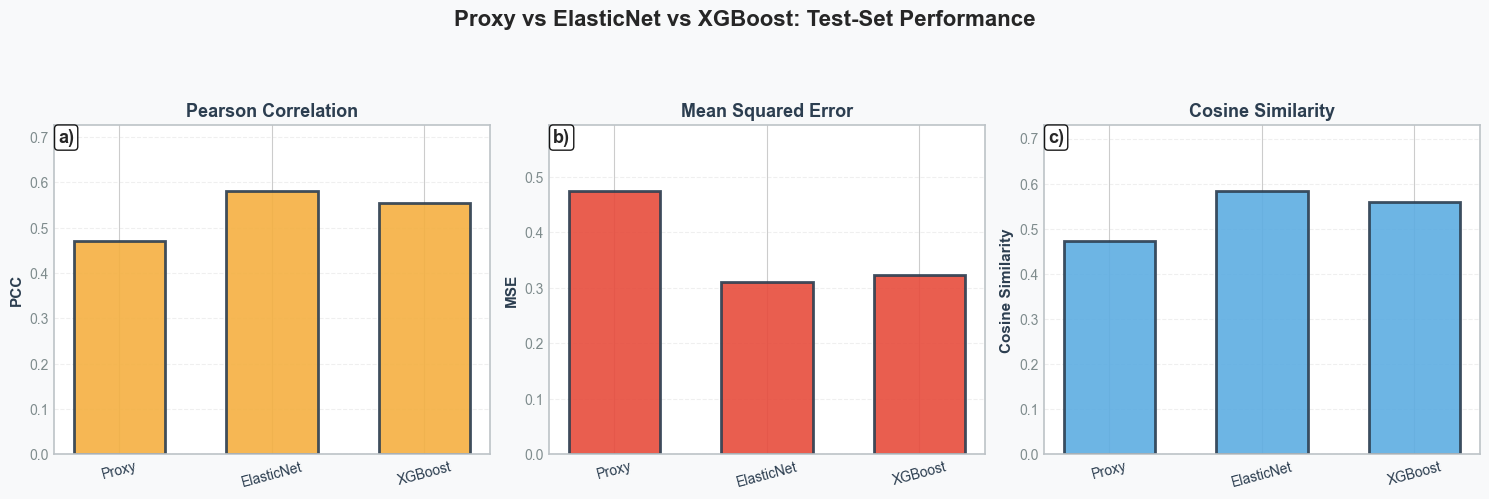

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\model_performance_test_plots\proxy_detailed_test_performance.png


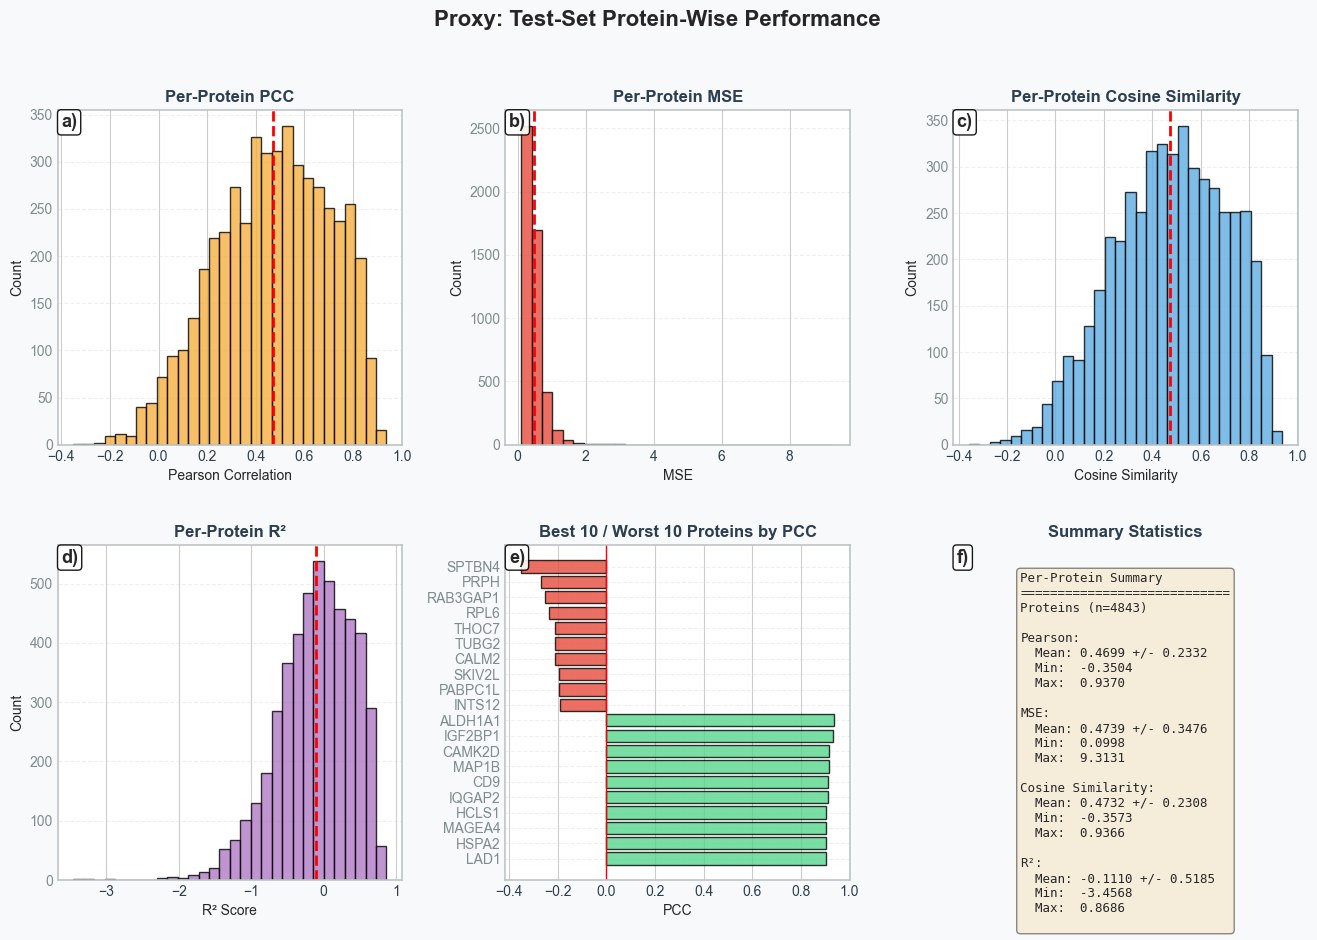

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\model_performance_test_plots\elasticnet_detailed_test_performance.png


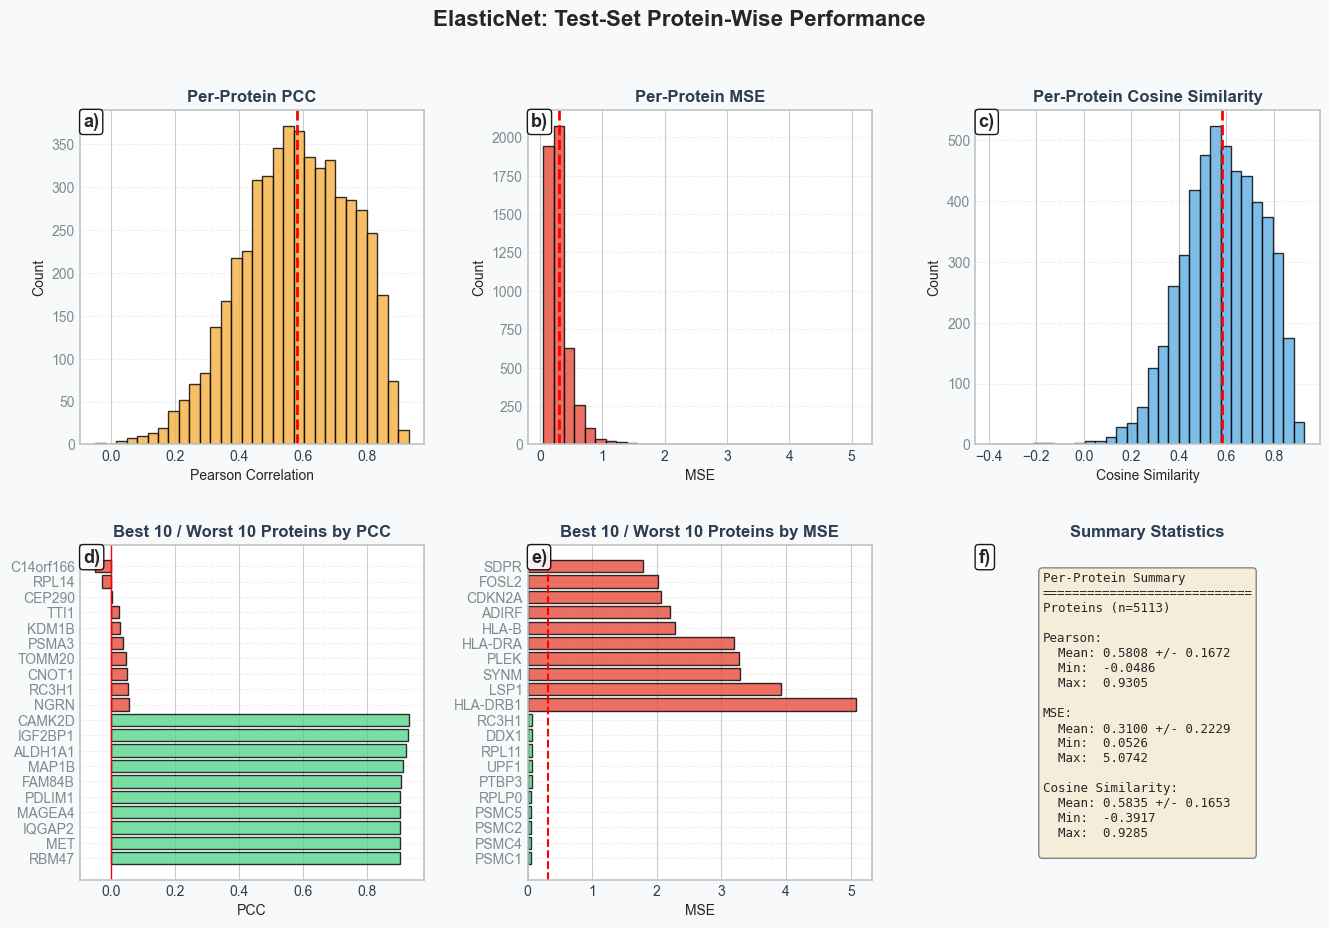

Saved: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\model_performance_test_plots\xgboost_detailed_test_performance.png


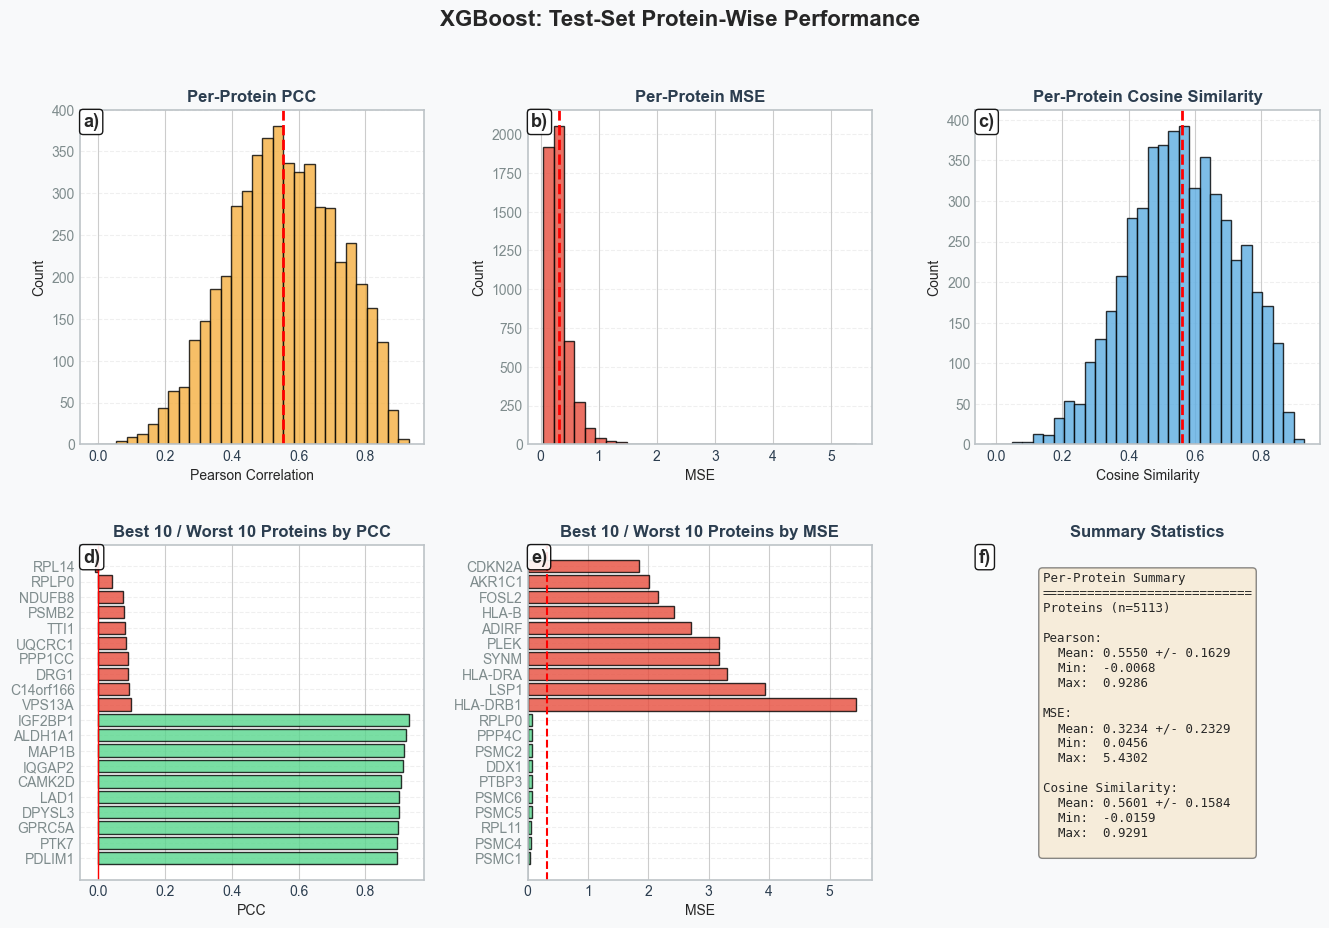

In [11]:
overall_plot_path = FIGURE_DIR / "proxy_enet_xgb_overall_test_performance.png" if SAVE_FIGURES else None
plot_overall_multi_model(
    summary_stats,
    out_path=overall_plot_path,
    title="Proxy vs ElasticNet vs XGBoost: Test-Set Performance",
)

for model_label, df in family_metric_tables.items():
    out = FIGURE_DIR / f"{model_label.lower().replace(' ', '_')}_detailed_test_performance.png" if SAVE_FIGURES else None
    if model_label == "Proxy":
        plot_detailed_model_proxy(df, model_label=model_label, out_path=out)
    else:
        plot_detailed_model_no_r2(df, model_label=model_label, out_path=out)


## Optional: export the plotting tables

In [12]:
if SAVE_FIGURES:
    for model_label, df in family_metric_tables.items():
        safe_name = model_label.lower().replace(" ", "_")
        df.to_csv(FIGURE_DIR / f"{safe_name}_metric_wise_best_test_performance.csv", index=False)
    all_results.to_csv(FIGURE_DIR / "all_results_with_proxy_test_metrics.csv", index=False)
    print("Exported plotting tables and combined result table to:", FIGURE_DIR)
else:
    print("SAVE_FIGURES is False; no tables were exported.")


Exported plotting tables and combined result table to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\model_performance_test_plots
